In [46]:

import numpy as np
import pandas as pd

g, rho_0, R = 9.81, 1.225, 287.05
glide_angle = np.radians(3)
threshold_elevation = 8.5344

aircraft_db = {
    "A320": {"Mass": 64000, "S": 122.6, "CD0": 0.024, "Wingspan": 35.8, "e": 0.85},
    "B738": {"Mass": 68000, "S": 125, "CD0": 0.026, "Wingspan": 35.8, "e": 0.84},
    "B789": {"Mass": 190000, "S": 325, "CD0": 0.022, "Wingspan": 60.1, "e": 0.86},
    "B77W": {"Mass": 250000, "S": 427.8, "CD0": 0.023, "Wingspan": 64.8, "e": 0.84}
}

for cfg in aircraft_db.values():
    cfg["AR"] = cfg["Wingspan"]**2 / cfg["S"]

aircraft_table = pd.DataFrame([
    [v["Mass"], v["S"], v["CD0"], v["Wingspan"], v["AR"], v["e"]]
    for v in aircraft_db.values()
], index=aircraft_db.keys(), columns=[
    "Mass (kg)", "Wing Area (m²)", "Zero-Lift CD",
    "Wingspan (m)", "Aspect Ratio", "Oswald Efficiency"
])

aircraft_table.index.name = "Aircraft"
print("AIRCRAFT REFERENCE DATABASE")
display(aircraft_table.round(3))

inbound_traffic = [
    {"Callsign": "IGO927", "Type": "A320", "Range_NM": 12, "EAS_kt": 160},
    {"Callsign": "AXB1077", "Type": "B738", "Range_NM": 8.5, "EAS_kt": 145},
    {"Callsign": "OMA223", "Type": "B789", "Range_NM": 22, "EAS_kt": 210},
    {"Callsign": "UAE530", "Type": "B77W", "Range_NM": 18.5, "EAS_kt": 190}
]

results = []

for ac in inbound_traffic:
    cfg = aircraft_db[ac["Type"]]
    d = ac["Range_NM"] * 1852
    eas = ac["EAS_kt"] * 0.514444
    h = d * np.tan(glide_angle) + threshold_elevation
    T = 288.15 - 0.0065 * h
    p = 101325 * (1 - 0.0065 * h / 288.15)**5.25588
    rho = p / (R * T)
    tas = eas * np.sqrt(rho_0 / rho)
    W = cfg["Mass"] * g
    cl = 2 * W * np.cos(glide_angle) / (rho * tas**2 * cfg["S"])
    k = 1 / (np.pi * cfg["AR"] * cfg["e"])
    cd = cfg["CD0"] + k * cl**2
    drag = 0.5 * rho * tas**2 * cfg["S"] * cd
    thrust = (drag - W * np.sin(glide_angle)) / 1000
    vsi = -tas * np.sin(glide_angle) * 196.8504

    results.append({
        "Callsign": ac["Callsign"], "Aircraft": ac["Type"],
        "Range (NM)": ac["Range_NM"], "Altitude (ft)": h * 3.28084,
        "EAS (kt)": ac["EAS_kt"], "TAS (kt)": tas / 0.514444,
        "Density (kg/m³)": rho, "CL": cl, "CD": cd,
        "Drag (kN)": drag / 1000, "Thrust (kN)": thrust,
        "VSI (fpm)": vsi
    })

df = pd.DataFrame(results)
print("\nCOK AIRCRAFT APPROACH ANALYSIS")
display(df.round(3))


AIRCRAFT REFERENCE DATABASE


,Mass (kg),Wing Area (m²),Zero-Lift CD,Wingspan (m),Aspect Ratio,Oswald Efficiency
Aircraft,,,,,,
A320,64000,122.6,0.024,35.8,10.454,0.85
B738,68000,125.0,0.026,35.8,10.253,0.84
B789,190000,325.0,0.022,60.1,11.114,0.86
B77W,250000,427.8,0.023,64.8,9.815,0.84



COK AIRCRAFT APPROACH ANALYSIS


,Callsign,Aircraft,Range (NM),Altitude (ft),EAS (kt),TAS (kt),Density (kg/m³),CL,CD,Drag (kN),Thrust (kN),VSI (fpm)
0,IGO927,A320,12.0,3849.229,160,169.397,1.093,1.232,0.078,39.889,7.031,-897.801
1,AXB1077,B738,8.5,2734.704,145,150.976,1.130,1.564,0.116,49.576,14.663,-800.170
2,OMA223,B789,22.0,7033.586,210,233.360,0.992,0.801,0.043,100.776,3.227,-1236.803
3,UAE530,B77W,18.5,5919.061,190,207.562,1.026,0.978,0.060,150.082,21.728,-1100.077


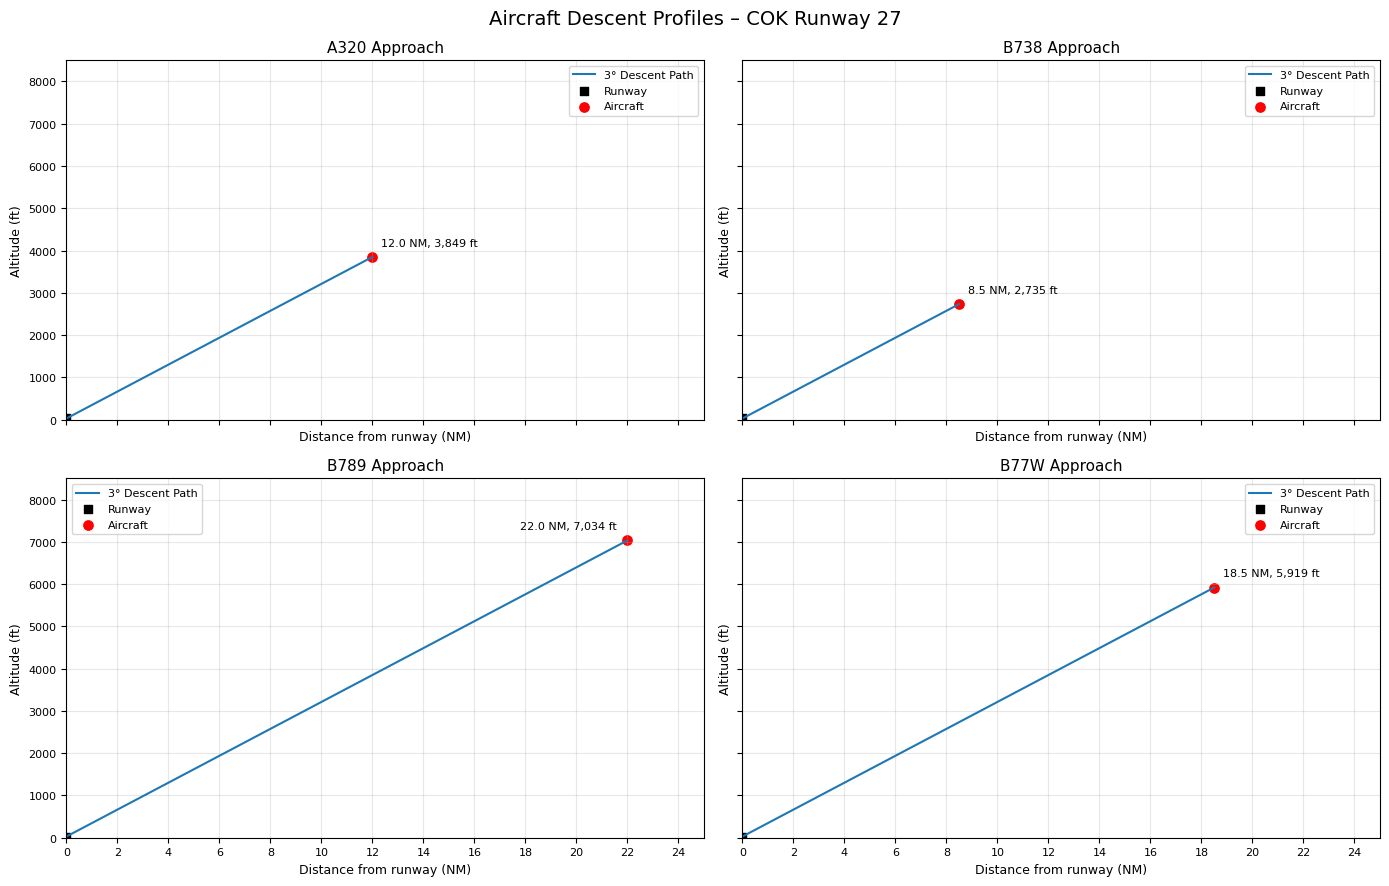

In [23]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)

for i, ax in enumerate(axes.flat):
    row = df.iloc[i]
    d, h = row["Range (NM)"], row["Altitude (ft)"]

    x = np.linspace(0, d, 100)
    y = (x * 1852 * np.tan(np.radians(3)) + 8.5344) / 0.3048

    ax.plot(x, y, label="3° Descent Path")
    ax.scatter(0, 28, color="black", marker="s", label="Runway")
    ax.scatter(d, h, color="red", s=45, label="Aircraft")

    ax.annotate(f"{d:.1f} NM, {h:,.0f} ft", (d, h),
            xytext=(-8, 8) if d > 20 else (6, 8),
            textcoords="offset points",
            ha="right" if d > 20 else "left", fontsize=8)
    ax.set_title(f'{row["Aircraft"]} Approach', fontsize=11)
    ax.set_xlim(0, 25)
    ax.set_ylim(0, 8500)
    ax.set_xticks(np.arange(0, 26, 2))
    ax.set_xlabel("Distance from runway (NM)", fontsize=9)
    ax.set_ylabel("Altitude (ft)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Aircraft Descent Profiles – COK Runway 27", fontsize=14)
plt.tight_layout()
plt.savefig("COK_Approach_Profiles.png", dpi=300, bbox_inches="tight")
plt.show()





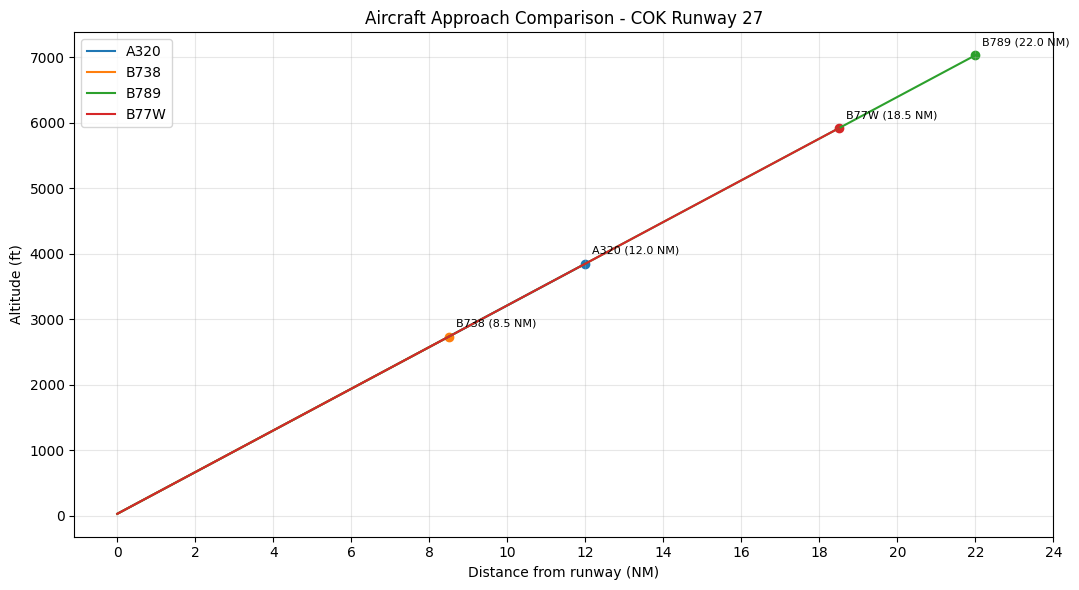

In [26]:
plt.figure(figsize=(11, 6))

for _, r in df.iterrows():
    x = np.linspace(0, r["Range (NM)"], 100)
    y = (x*1852*np.tan(np.radians(3))+8.5344)/0.3048
    plt.plot(x, y, label=r["Aircraft"])
    plt.scatter(r["Range (NM)"], r["Altitude (ft)"])
    plt.annotate(f'{r["Aircraft"]} ({r["Range (NM)"]:.1f} NM)',
                 (r["Range (NM)"], r["Altitude (ft)"]),
                 xytext=(5, 7), textcoords="offset points", fontsize=8)

plt.xlabel("Distance from runway (NM)")
plt.ylabel("Altitude (ft)")
plt.title("Aircraft Approach Comparison - COK Runway 27")
plt.xticks(np.arange(0, 26, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()




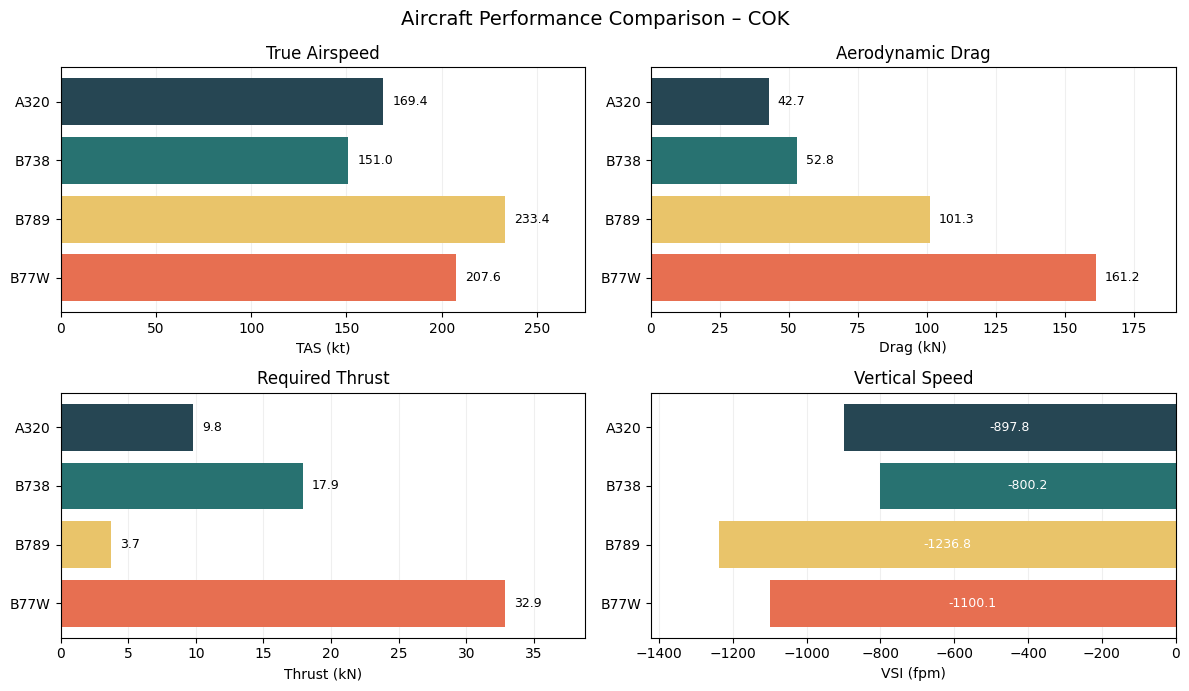

In [33]:

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

charts = [
    ("TAS (kt)", "True Airspeed"),
    ("Drag (kN)", "Aerodynamic Drag"),
    ("Thrust (kN)", "Required Thrust"),
    ("VSI (fpm)", "Vertical Speed")
]

for ax, (col, title) in zip(axes.flat, charts):
    bars = ax.barh(df["Aircraft"], df[col],
               color=["#264653", "#287271", "#E9C46A", "#E76F51"])

    ax.set_title(title)
    ax.set_xlabel(col)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.invert_yaxis()

    for bar, value in zip(bars, df[col]):
        if col == "VSI (fpm)":
            ax.text(value / 2, bar.get_y() + bar.get_height()/2,
                    f"{value:.1f}", ha="center", va="center",
                    color="white", fontsize=9)
        else:
            ax.text(value + max(df[col]) * 0.02,
                    bar.get_y() + bar.get_height()/2,
                    f"{value:.1f}", va="center", fontsize=9)

    if col != "VSI (fpm)":
        ax.set_xlim(0, max(df[col]) * 1.18)
    else:
        ax.set_xlim(min(df[col]) * 1.15, 0)

plt.suptitle("Aircraft Performance Comparison – COK", fontsize=14)
plt.tight_layout()
plt.savefig("COK_Performance_Comparison.png", dpi=300)
plt.show()



In [34]:

required = ["Aircraft", "Range (NM)", "Altitude (ft)", "TAS (kt)",
            "CL", "CD", "Drag (kN)", "Thrust (kN)", "VSI (fpm)"]

assert all(c in df.columns for c in required)
assert len(df) == 4
assert np.isfinite(df[required[1:]].to_numpy()).all()
assert (df["Altitude (ft)"] > 28).all()
assert (df["TAS (kt)"] > 0).all()
assert (df["CL"] > 0).all() and (df["CD"] > 0).all()
assert (df["Drag (kN)"] > 0).all()
assert (df["VSI (fpm)"] < 0).all()

print("MODEL VALIDATION PASSED")
print("All four aircraft results passed the basic checks.")

MODEL VALIDATION PASSED
All four aircraft results passed the basic checks.


In [47]:
print("RESULTS INTERPRETATION")

print("Highest Drag:",
      df.loc[df["Drag (kN)"].idxmax(), "Aircraft"])

print("Highest Thrust Requirement:",
      df.loc[df["Thrust (kN)"].idxmax(), "Aircraft"])

print("Highest Rate of Descent:",
      df.loc[df["VSI (fpm)"].abs().idxmax(), "Aircraft"])

print("Highest True Airspeed:",
      df.loc[df["TAS (kt)"].idxmax(), "Aircraft"])

RESULTS INTERPRETATION
Highest Drag: B77W
Highest Thrust Requirement: B77W
Highest Rate of Descent: B789
Highest True Airspeed: B789


COK Terminal Approach – Aircraft Flight Mechanics Analysis

# **1. Project Overview**

This project is based on the study of aircraft flight mechanics during a simplified terminal approach to Cochin International Airport (COK), India. Python was used to carry out the calculations and analyse the flight characteristics of different aircraft during descent.

The study includes four commercial aircraft:

# Airbus A320

Boeing 737-800 (B738)

Boeing 787-9 (B789)

Boeing 777-300ER (B77W)

For the analysis, a simplified 3-degree descent path was considered. Different flight and aerodynamic parameters, such as altitude, true airspeed, lift coefficient, drag coefficient, thrust requirement, and vertical speed, were calculated.

Python helped in performing these calculations, arranging the results, and creating graphs to compare the four aircraft.

The main purpose of this project is to get a better understanding of flight mechanics and see how the concepts studied in theory can be applied through a practical computational model.

# 2. Project Objectives

The main objectives of this project are:

To develop a simplified 3-degree descent model for different aircraft.

To calculate atmospheric properties using the International Standard Atmosphere (ISA) model.

To estimate true airspeed by considering changes in air density.

To calculate lift and drag coefficients for the selected aircraft.

To estimate the thrust required during descent.

To determine the vertical speed of aircraft along the descent path.

To compare the calculated flight parameters using graphs generated with Python.

# 3. Aircraft Configurations

For this project, four commercial aircraft were selected to include both narrow-body and wide-body aircraft.

Aircraft	Configuration

A320	Narrow-body passenger aircraft

B738	Narrow-body passenger aircraft

B789	Wide-body passenger aircraft

B77W	Wide-body passenger aircraft

Each aircraft is represented using different input parameters, including mass, wing area, zero-lift drag coefficient, wingspan, and Oswald efficiency factor. The aspect ratio is calculated using the wingspan and wing area of each aircraft.

The aircraft scenarios and callsigns used in this project are hypothetical. They have been created only for simulation purposes and do not represent actual aircraft movements or radar surveillance data.

# 4. Methodology

The project was carried out by following a series of steps. First, the descent path was defined, and then the atmospheric and aerodynamic parameters were calculated.


Approach Geometry: A constant 3-degree descent angle was assumed for all four aircraft. The altitude at different distances from the runway threshold was then calculated.

Atmospheric Model: ISA equations were used to estimate atmospheric temperature, pressure, and air density at different altitudes.

Airspeed Estimation: True airspeed was calculated from equivalent airspeed by taking the variation in air density into account.

Lift Calculation: The lift coefficient was estimated using a simplified steady-descent lift-equilibrium approach.

Drag Calculation: The drag coefficient was calculated using the parabolic drag polar equation.

Thrust Estimation: A simplified force-equilibrium equation was used to estimate the thrust required by the aircraft during descent.

Vertical Speed: The vertical speed was calculated using the true airspeed and the assumed descent angle.

These steps were used to obtain the required flight parameters and compare the results for the selected aircraft.

# 5. Assumptions and Limitations


Since this project uses a simplified model, a few assumptions were made to make the calculations easier to carry out.

The main assumptions are:

All aircraft are assumed to maintain a constant 3-degree descent angle.

Aircraft mass is considered constant throughout the simulation.

Simplified aerodynamic parameters are used for the calculations.

Standard ISA atmospheric conditions are assumed.

Wind and turbulence effects are not included.

Changes in aircraft configuration, such as flap deployment and landing gear extension, are not considered.

Aircraft control systems and detailed flight dynamics are not included in the model.

Actual flight recorder data and radar surveillance data are not used.


Because of these assumptions, the calculated values may differ from the actual performance of an aircraft. The results are mainly intended to understand the basic concepts of aircraft performance during descent and should not be used for real-world flight planning.

# 6. Computing Resources


The following tools and Python libraries were used while developing the project:

Python: Used to write the program and perform the required calculations.

Google Colab: Used as the platform for writing and running the Python code.

NumPy: Used for numerical calculations.

Pandas: Used to organize and manage the calculated data.

Matplotlib: Used to create graphs and compare the results visually.

# 7. Project Development and Learning

Python was used throughout the project to develop the model and carry out the calculations. Different libraries were used depending on the requirements, such as numerical calculations, handling data, and preparing graphs.

During the development process, I worked on understanding the flight mechanics equations and learning how to implement them using Python. I also checked the outputs generated by the program and made changes wherever needed.

One of the interesting parts of this project was applying theoretical concepts to an actual aircraft-related simulation. It helped me understand how aerodynamic principles and aircraft characteristics influence flight parameters during descent.

Overall, this project gave me a chance to improve my Python programming skills while gaining a better understanding of aircraft flight mechanics.

# 8. References

The following resources were used to understand the basic concepts of flight mechanics, aerodynamics, and aircraft characteristics:

NASA Glenn Research Center – Lift Equation: https://www1.grc.nasa.gov/beginners-guide-to-aeronautics/lift-equation/

NASA Glenn Research Center – Drag Equation: https://www1.grc.nasa.gov/beginners-guide-to-aeronautics/drag-equation/

NASA Glenn Research Center – Lift-to-Drag Ratio: https://www1.grc.nasa.gov/beginners-guide-to-aeronautics/lift-to-drag-ratio/

Federal Aviation Administration – Pilot's Handbook of Aeronautical Knowledge: https://www.faa.gov/regulations_policies/handbooks_manuals/aviation/phak

Airbus – Aircraft Characteristics: https://www.aircraft.airbus.com/en/customer-care/fleet-wide-care/airport-operations-and-aircraft-characteristics/aircraft-characteristics

Boeing – Airplane Characteristics for Airport Planning: https://www.boeing.com/commercial/airports/plan-manuals

Note: These references were used to understand the concepts and aircraft characteristics considered in the project.

# 9. Results and Visualisation

After running the Python program, the calculated flight and aerodynamic parameters for all four aircraft were obtained.

Graphs were created to make it easier to understand the results and compare the aircraft. The main parameters presented in the graphs include:

Aircraft descent profiles and altitude at different distances from the runway.
True airspeed during descent.


Aerodynamic drag.

Estimated thrust requirement.

Vertical speed during descent.

# 10. Observations

After comparing the results obtained from the simulation, the following observations were made:

The Boeing 777-300ER (B77W) shows the highest estimated aerodynamic drag among the four aircraft.

The Boeing 777-300ER (B77W) also has the highest estimated thrust requirement in the selected scenarios.

The Boeing 787-9 (B789) records the highest calculated true airspeed.

The Boeing 787-9 (B789) also shows the highest magnitude of vertical speed.

All four aircraft follow the same assumed 3-degree descent angle, so their descent profiles have the same slope. However, the distance and altitude considered for each aircraft vary in the simulation.

These observations are based on the calculated values obtained from the model. The comparison helps demonstrate how flight mechanics equations can be applied to different aircraft configurations. It does not represent a comparison of their actual performance during real-world operations.

# 11. Basic Model Validation

Once the calculations were completed, some basic checks were performed to make sure that the Python model was generating consistent results.

The following checks were carried out:

Checked whether all the required output variables were generated.
Verified that all four aircraft configurations were included in the analysis.
Checked whether the numerical outputs contained finite values.
Confirmed that altitude, true airspeed, lift coefficient, drag coefficient, and drag values were positive.
Checked whether the vertical speed values indicated that the aircraft were descending.
Validation Result: All the basic sanity checks implemented in the model were passed successfully.

These checks helped confirm that the calculated outputs met the selected numerical and physical conditions. However, passing these checks does not necessarily mean that the model produces completely accurate real-world results. The calculations have not been compared with actual aircraft performance or flight data.

# 12. Conclusion

Through this project, I was able to study the basic principles of aircraft flight mechanics by developing a simplified terminal approach simulation for Cochin International Airport.

The analysis included four commercial aircraft, namely the Airbus A320, Boeing 737-800, Boeing 787-9, and Boeing 777-300ER. A constant 3-degree descent path was assumed for the simulation.

Using Python, different flight and aerodynamic parameters were calculated, including atmospheric properties, true airspeed, lift coefficient, drag coefficient, aerodynamic drag, thrust requirement, and vertical speed.

The graphs generated from the calculations helped in understanding how the selected aircraft differ in terms of their calculated flight parameters.

One of the main things I learned from this project was how to convert theoretical flight mechanics equations into a working Python model. It also helped me understand the relationship between aircraft characteristics, atmospheric conditions, and flight performance during descent.

Although the model has certain limitations due to the assumptions made, it provides a good starting point for studying aircraft performance using basic computational methods.

# 13. Possible Enhancements

There are several improvements that could be made to this project in the future:

Using more accurate and reliable aircraft aerodynamic data.

Improving the airspeed conversion method.

Including atmospheric variations and wind effects in the calculations.

Considering different flap and landing gear configurations.

Comparing the simulation results with published aircraft performance data.

Extending the model to include more detailed aircraft flight dynamics.


